# 04 · Especialização com LoRA

**Por que LoRA?** Em vez de reescrever todos os ~1,5 bilhão de pesos, treinamos matrizes pequenas (rank 16)
acopladas às camadas de atenção e MLP — cerca de 1% dos parâmetros. Cabe numa GPU de 8 GB e treina em minutos.

**O que o LoRA aprende aqui** (o conhecimento continua vindo da busca):
1. responder **sempre** no JSON do contrato;
2. escolher e **citar o trecho certo** entre 3 trechos (2 são distratores);
3. **recusar** quando o contexto não responde.

**Dados:** 94 exemplos de resposta (2 perguntas de treino por trecho) + 25 recusas fora do escopo = 119 exemplos,
gerados com o **mesmo prompt de produção**. Nenhuma pergunta do teste entra no treino (checagem abaixo).

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("../src")); sys.path.insert(0, os.path.abspath("../scripts"))
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
%run ../scripts/gerar_dataset_lora.py --backend e5

W1112 16:18:14.902000 7636 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

119 exemplos gravados em treino/sft.jsonl (94 respostas, 25 recusas)


Checagem de vazamento: {"perguntas_identicas": 0, "similaridade_max_media": 0.209, "similaridade_max_maior": 0.404, "par_mais_parecido": {"teste": "Quanto custa solicitar o reparo de um buraco na rua?", "treino": "Como funciona o conserto de um buraco na rua?"}}


In [3]:
json.load(open("../avaliacao/resultados/vazamento.json", encoding="utf-8"))

{'perguntas_identicas': 0,
 'similaridade_max_media': 0.209,
 'similaridade_max_maior': 0.404,
 'par_mais_parecido': {'teste': 'Quanto custa solicitar o reparo de um buraco na rua?',
  'treino': 'Como funciona o conserto de um buraco na rua?'}}

## Treino (≈ 5–15 min numa RTX de 8 GB)

In [4]:
%run ../scripts/treinar_lora.py --epocas 3 --rank 16

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Epoch,Training Loss,Validation Loss
1,0.028398,0.029773
2,0.014195,0.021700
3,0.006508,0.017388


Adaptador salvo em C:\Users\guili\Desktop\zelacidade-genai\modelos\lora-zela


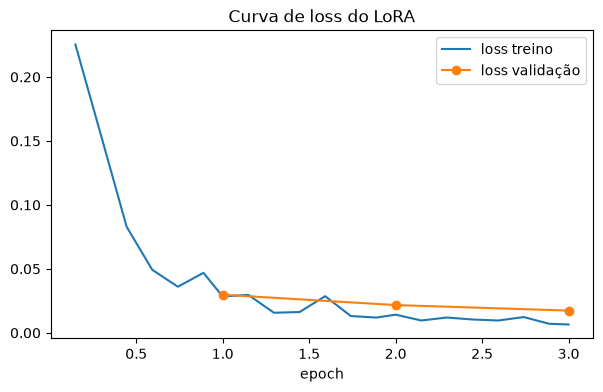

{'modelo': 'Qwen/Qwen2.5-1.5B-Instruct', 'saida': 'C:\\Users\\guili\\Desktop\\zelacidade-genai\\modelos\\lora-zela', 'epocas': 3.0, 'rank': 16, 'lr': 0.0002} | treino: 108 | validação: 11


In [5]:
hist = json.load(open("../avaliacao/resultados/lora_historico.json", encoding="utf-8"))
log = pd.DataFrame(hist["log"])
fig, ax = plt.subplots(figsize=(7, 4))
log.dropna(subset=["loss"]).plot(x="epoch", y="loss", ax=ax, label="loss treino")
if "eval_loss" in log:
    log.dropna(subset=["eval_loss"]).plot(x="epoch", y="eval_loss", ax=ax, marker="o", label="loss validação")
ax.set_title("Curva de loss do LoRA"); plt.show()
print(hist["args"], "| treino:", hist["n_treino"], "| validação:", hist["n_val"])